In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA658726/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,aliquot,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,⋯,periodontitis,Platform,ReleaseDate,create_date,version,Sample.Name,sample_type,smoking,SRA.Study,strain
,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
1,SRR12522728,cig10,AMPLICON,1392,1029499513,PRJNA658726,SAMN15887573,Metagenome or environmental,964901738,UAEU,⋯,moderate-severe,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T12:11:00Z,1,C76,Subgingival,S-Cigarettes,SRP278853,mixed
2,SRR12522729,cig9,AMPLICON,1413,666237131,PRJNA658726,SAMN15887572,Metagenome or environmental,623189288,UAEU,⋯,no-mild,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T11:52:00Z,1,C75,Subgingival,S-Cigarettes,SRP278853,mixed
3,SRR12522730,cig8,AMPLICON,1405,773831776,PRJNA658726,SAMN15887571,Metagenome or environmental,726664933,UAEU,⋯,no-mild,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T11:52:00Z,1,C55,Subgingival,S-Cigarettes,SRP278853,mixed
4,SRR12522731,cig7,AMPLICON,1396,514482951,PRJNA658726,SAMN15887570,Metagenome or environmental,483294191,UAEU,⋯,moderate-severe,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T11:55:00Z,1,C51,Subgingival,S-Cigarettes,SRP278853,mixed
5,SRR12522732,cig6,AMPLICON,1377,593175486,PRJNA658726,SAMN15887569,Metagenome or environmental,557099312,UAEU,⋯,moderate-severe,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T11:57:00Z,1,C49,Subgingival,S-Cigarettes,SRP278853,mixed
6,SRR12522733,cig5,AMPLICON,1399,806379018,PRJNA658726,SAMN15887568,Metagenome or environmental,756584106,UAEU,⋯,no-mild,OXFORD_NANOPORE,2021-09-30T00:00:00Z,2020-09-03T11:53:00Z,1,C38,Subgingival,S-Cigarettes,SRP278853,mixed


[1] "Run"                            "aliquot"                       
 [3] "Assay.Type"                     "AvgSpotLen"                    
 [5] "Bases"                          "BioProject"                    
 [7] "BioSample"                      "BioSampleModel"                
 [9] "Bytes"                          "Center.Name"                   
[11] "Collection_Date"                "Consent"                       
[13] "DATASTORE.filetype"             "DATASTORE.provider"            
[15] "DATASTORE.region"               "Experiment"                    
[17] "geo_loc_name_country"           "geo_loc_name_country_continent"
[19] "geo_loc_name"                   "HOST"                          
[21] "Instrument"                     "isolate"                       
[23] "isolation_source"               "lat_lon"                       
[25] "Library.Name"                   "LibraryLayout"                 
[27] "LibrarySelection"               "LibrarySource"                 
[29] "Organism"                       "periodontitis"                 
[31] "Platform"                       "ReleaseDate"                   
[33] "create_date"                    "version"                       
[35] "Sample.Name"                    "sample_type"                   
[37] "smoking"                        "SRA.Study"                     
[39] "strain"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V6-V8',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$sample_type,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study",
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 40
[1] 40


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA658726,SRR12522728,C76,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO
2,PRJNA658726,SRR12522729,C75,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO
3,PRJNA658726,SRR12522730,C55,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO
4,PRJNA658726,SRR12522731,C51,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO
5,PRJNA658726,SRR12522732,C49,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO
6,PRJNA658726,SRR12522733,C38,NA,NA,NA,V6-V8,OXFORD_NANOPORE,United Arab Emirates,Subgingival,2021-09-30T00:00:00Z,NA,The impact of smoking different tobacco types on the subgingival microbiome and periodontal health: a pilot study,NO,NA,NO


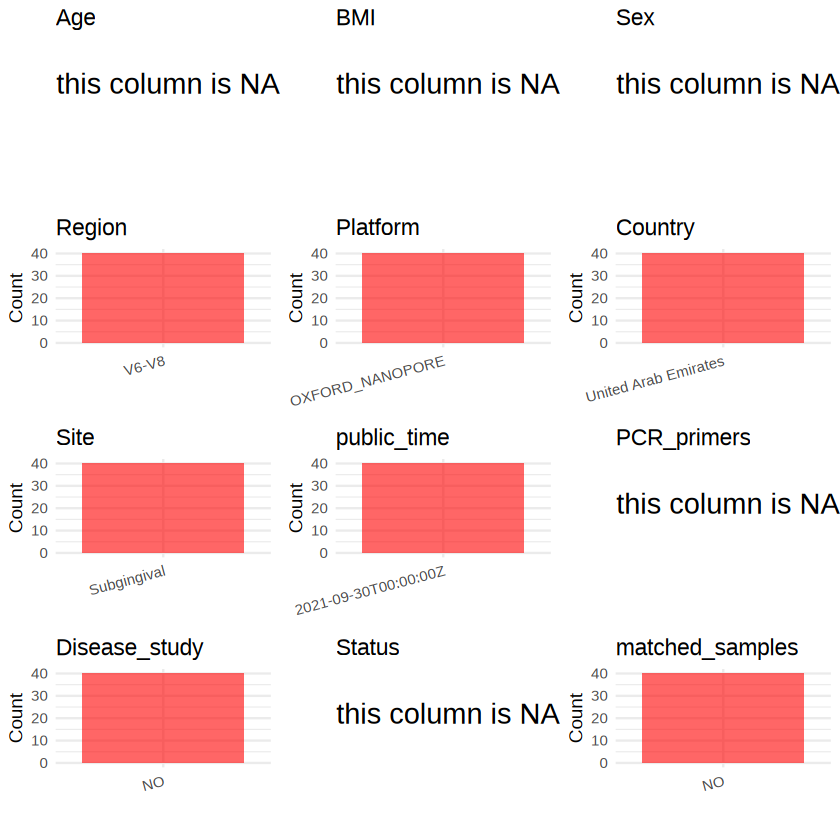

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA658726/metadata.csv", quote = T)